# Weekly Net-Revenue Forecasting

## tl;dr

A 52-week seasonal naïve forecast beat Exponential Smoothing, SARIMA, Gradient Boosting, and XGBoost during rolling backtests. The frozen 16-week holdout achieved MAE of approximately 47,055 and sMAPE of 18.3%. Complexity was not rewarded merely for being complex.

## Context & Methods

The target is weekly net revenue: valid sales value less cancellation/return value. The first and last partial calendar weeks are excluded. Models are selected using repeated expanding-window forecasts and evaluated on the latest 16 complete weeks only after selection.

### Key assumptions

- Revenue uses the source currency; no currency conversion is available.
- Future orders and active customers are unknown, so they are not forecast features.
- Machine-learning lags and rolling features use prior weeks only.
- The empirical 80% range uses historical backtest errors and is not guaranteed.

In [1]:
from pathlib import Path
import json, os, sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT)); os.chdir(ROOT)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.forecasting import complete_weekly_series, run_forecasting
sns.set_theme(style='whitegrid')

## Data

### 1. Prepare complete weekly observations

Raw weekly rows: 106
Complete weekly rows: 104


,invoice_week,gross_revenue,returned_value,net_revenue
0,2009-12-07,234033.21,8894.34,225138.87
1,2009-12-14,251561.06,2470.17,249090.89
2,2009-12-21,51715.49,1847.01,49868.48
3,2009-12-28,0.00,0.00,0.00
4,2010-01-04,166010.79,1288.94,164721.85


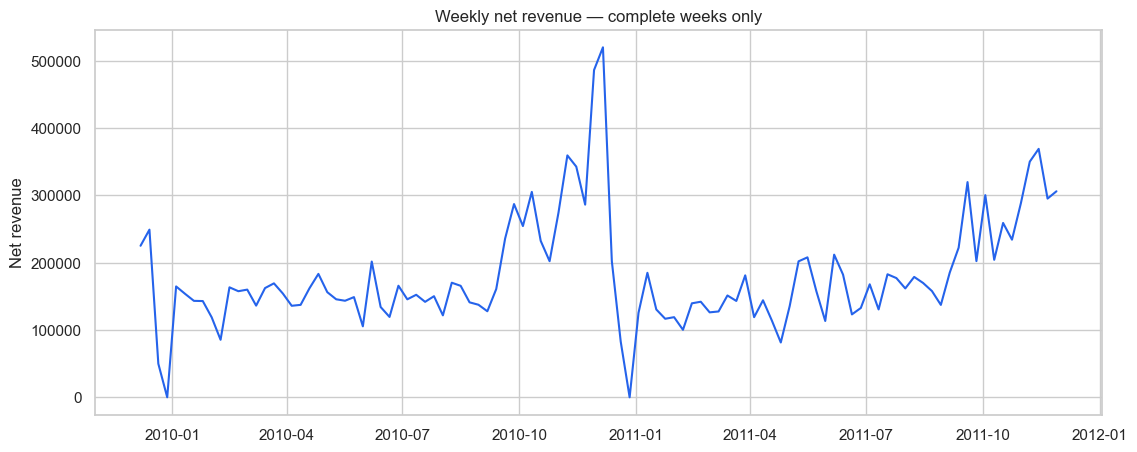

In [2]:
raw_weekly = pd.read_parquet(ROOT / 'data/processed/weekly_revenue.parquet')
weekly = complete_weekly_series(raw_weekly)
print(f'Raw weekly rows: {len(raw_weekly)}')
print(f'Complete weekly rows: {len(weekly)}')
display(weekly[['invoice_week','gross_revenue','returned_value','net_revenue']].head())
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(weekly['invoice_week'],weekly['net_revenue'],color='#2563EB')
ax.set(title='Weekly net revenue — complete weeks only',xlabel='',ylabel='Net revenue')
plt.show()

### 2. Confirm lag features stop before the forecast week

In [3]:
from src.forecasting import make_supervised
supervised = make_supervised(weekly)
display(supervised.head())
assert (supervised['lag_1'] != supervised['net_revenue']).any()
print('Lag and rolling features are shifted before model fitting.')

,invoice_week,net_revenue,lag_1,lag_2,lag_4,lag_8,lag_13,rolling_mean_4,rolling_std_4,rolling_mean_8,rolling_std_8,rolling_mean_13,rolling_std_13,week_sin,week_cos,month,quarter
0,2010-03-08,136209.68,159999.51,157627.65,85458.28,153808.59,225138.87,141625.1800,37519.879898,140682.40250,26424.966713,139559.946923,66064.028456,0.935016,3.546049e-01,3,1
1,2010-03-15,162282.81,136209.68,159999.51,163415.28,143302.08,249090.89,154313.0300,12300.474203,138482.53875,25903.516873,132719.240000,60863.648125,0.970942,2.393157e-01,3,1
2,2010-03-22,169308.66,162282.81,136209.68,157627.65,142997.79,49868.48,154029.9125,12031.220677,140855.13000,27242.657528,126041.695385,50993.939899,0.992709,1.205367e-01,3,1
3,2010-03-29,154243.88,169308.66,162282.81,159999.51,118850.04,0.00,156950.1650,14383.274133,144143.98875,29065.483621,135229.401538,46705.525267,1.000000,-1.608123e-16,3,1
4,2010-04-05,135980.53,154243.88,169308.66,136209.68,85458.28,164721.85,155511.2575,14263.933290,148568.21875,27305.807436,147094.315385,23132.484534,0.992709,-1.205367e-01,4,2


Lag and rolling features are shifted before model fitting.


## Rolling Backtest

### 3. Execute all forecasting methods

In [4]:
metadata = run_forecasting(ROOT / 'reports/generated')
print(json.dumps(metadata,indent=2))

{
  "selected_model": "seasonal_naive_52",
  "selection_metric": "rolling_backtest_mae",
  "complete_weeks": 104,
  "development_weeks": 88,
  "final_test_weeks": 16,
  "train_reference_end_index": 72,
  "final_test_period_start": "2011-08-15T00:00:00",
  "final_test_period_end": "2011-11-28T00:00:00",
  "final_test_metrics": {
    "mae": 47055.462499999994,
    "rmse": 65722.1656044459,
    "smape": 18.293058395584797
  },
  "forecast_horizon_weeks": 8,
  "interval_method": "10th and 90th percentiles of rolling-backtest residuals",
  "limitations": [
    "Only 104 complete weekly observations are available.",
    "The source covers one historical retailer and excludes external drivers.",
    "The 80% range is empirical and not a guaranteed coverage interval."
  ]
}


### 4. Compare average rolling-backtest errors

,model,folds,mae_mean,mae_std,rmse_mean,smape_mean
0,seasonal_naive_52,8,"26,820.40","14,642.07","30,493.83",18.08
1,moving_average_4,8,"32,105.99","16,653.84","36,772.26",21.26
2,xgboost,8,"35,416.48","25,003.32","39,610.39",24.23
3,gradient_boosting,8,"38,703.97","26,319.15","43,449.93",24.90
4,sarima,8,"44,847.94","39,994.07","48,135.70",43.61
5,last_value,8,"47,546.15","40,632.43","51,768.57",45.10
6,exponential_smoothing,8,"50,480.11","30,218.45","56,148.52",42.05


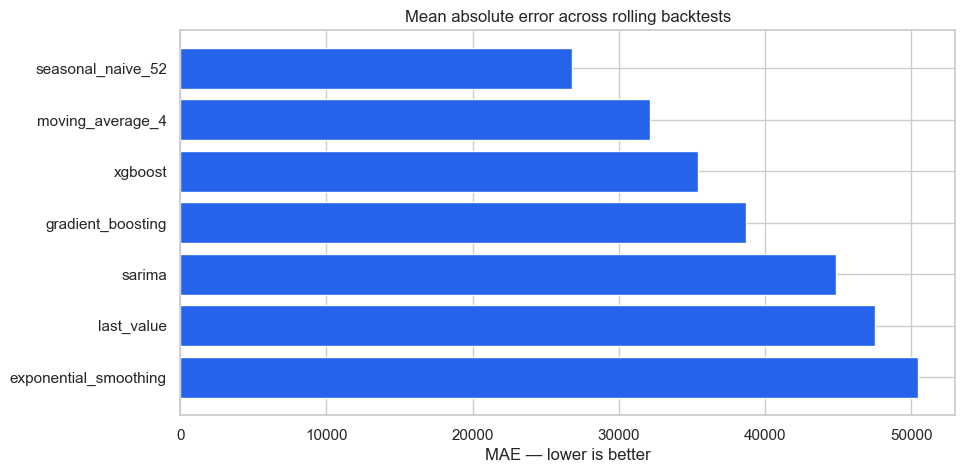

In [5]:
comparison = pd.read_csv(ROOT / 'reports/generated/forecast_model_comparison.csv')
display(comparison.style.format({c:'{:,.2f}' for c in comparison.columns if c not in ['model','folds']}))
plot = comparison.sort_values('mae_mean',ascending=False)
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(plot['model'],plot['mae_mean'],color='#2563EB')
ax.set(title='Mean absolute error across rolling backtests',xlabel='MAE — lower is better',ylabel='')
plt.show()

A sophisticated model must beat the baselines consistently. The selected seasonal naïve model predicts each week from the corresponding week 52 weeks earlier.

### 5. Inspect stability across forecast origins

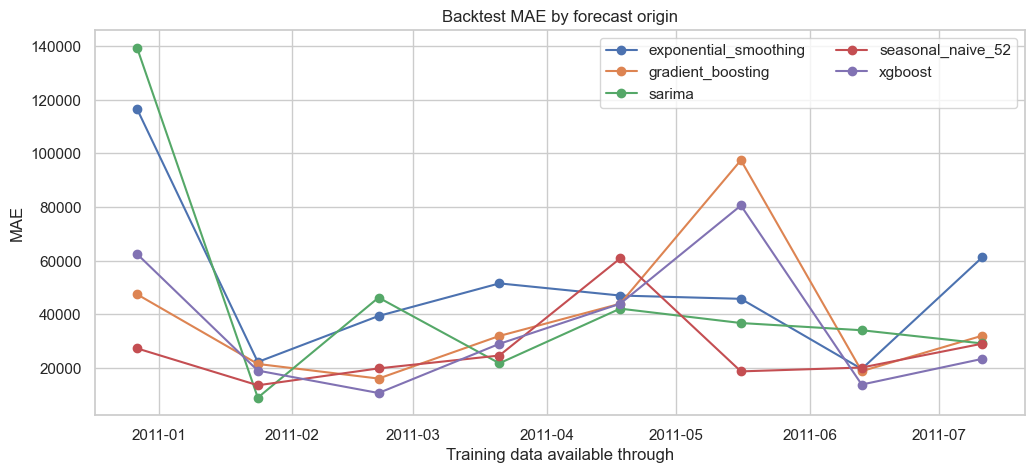

In [6]:
folds = pd.read_csv(ROOT / 'reports/generated/forecast_backtest_metrics.csv',parse_dates=['cutoff'])
selected = metadata['selected_model']
focus = folds.loc[folds['model'].isin([selected,'exponential_smoothing','sarima','gradient_boosting','xgboost'])]
fig, ax = plt.subplots(figsize=(12,5))
for name, frame in focus.groupby('model'):
    ax.plot(frame['cutoff'],frame['mae'],marker='o',label=name)
ax.set(title='Backtest MAE by forecast origin',xlabel='Training data available through',ylabel='MAE')
ax.legend(ncol=2); plt.show()

## Frozen Holdout

### 6. Evaluate the selected model on the latest 16 complete weeks

,Final holdout
mae,47055.462500
rmse,65722.165604
smape,18.293058


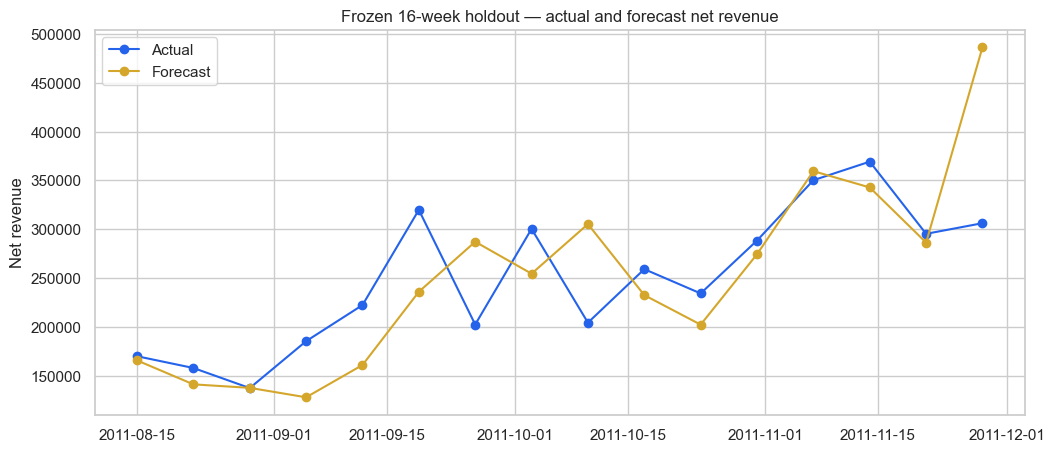

In [7]:
holdout = pd.read_parquet(ROOT / 'reports/generated/forecast_final_test_predictions.parquet')
display(pd.Series(metadata['final_test_metrics'],name='Final holdout').to_frame())
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(holdout['invoice_week'],holdout['net_revenue'],marker='o',label='Actual',color='#2563EB')
ax.plot(holdout['invoice_week'],holdout['predicted_net_revenue'],marker='o',label='Forecast',color='#D4A72C')
ax.set(title='Frozen 16-week holdout — actual and forecast net revenue',xlabel='',ylabel='Net revenue')
ax.legend(); plt.show()

MAE is expressed in source-currency units. RMSE is higher because it penalizes large weekly misses. sMAPE gives a percentage-like error but should not be read as a guaranteed percentage accuracy.

## Revenue Outlook

### 7. Display the eight-week point forecast and empirical range

,invoice_week,forecast_net_revenue,lower_80,upper_80
0,2011-12-05,519999.40,486292.097,560881.604
1,2011-12-12,202183.98,168476.677,243066.184
2,2011-12-19,82700.53,48993.227,123582.734
3,2011-12-26,0.00,0.000,40882.204
4,2012-01-02,125553.17,91845.867,166435.374
5,2012-01-09,184963.94,151256.637,225846.144
6,2012-01-16,130490.66,96783.357,171372.864
7,2012-01-23,116701.05,82993.747,157583.254


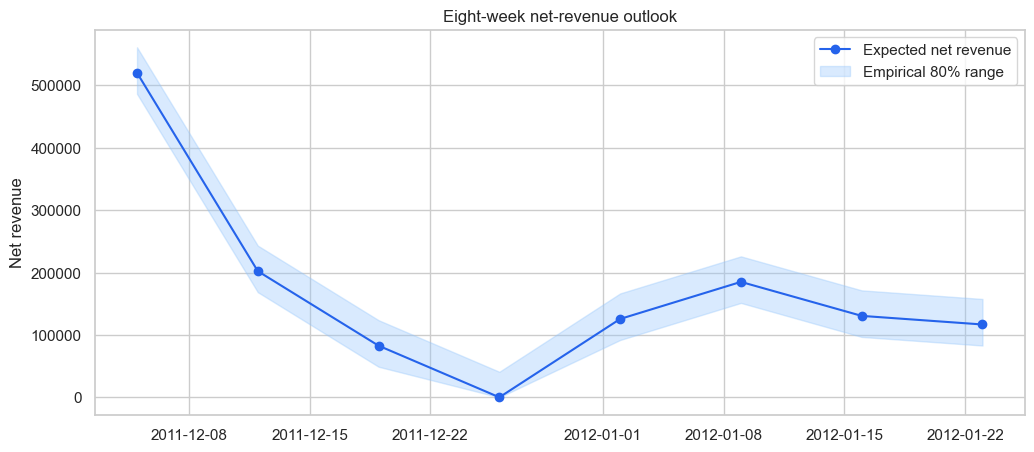

In [8]:
future = pd.read_parquet(ROOT / 'data/processed/revenue_forecast.parquet')
display(future)
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(future['invoice_week'],future['forecast_net_revenue'],marker='o',color='#2563EB',label='Expected net revenue')
ax.fill_between(future['invoice_week'],future['lower_80'],future['upper_80'],color='#93C5FD',alpha=.35,label='Empirical 80% range')
ax.set(title='Eight-week net-revenue outlook',xlabel='',ylabel='Net revenue')
ax.legend(); plt.show()

## Limitations

- Only 104 complete weeks are available.
- The annual seasonal baseline is supported by roughly two cycles only.
- Promotions, prices, inventory, holidays, marketing, and macroeconomic drivers are unavailable.
- The dataset is historical and represents one retailer.
- The empirical interval may not achieve 80% coverage in a changed environment.

## Takeaways

- The simple annual seasonal baseline won the rolling comparison.
- XGBoost and Gradient Boosting did not justify their added complexity.
- Final holdout error is reported separately from model-selection backtests.
- Forecast ranges communicate uncertainty and should not be treated as guarantees.
- A production forecast would require more history and external business drivers.